# Trabajo Práctico 02 — Procesos ETL

**Bases de Datos Masivas (11088)** — Departamento de Ciencias Básicas
**2° Cuatrimestre 2026** — Universidad Nacional de Luján

---

**Alumno/a:** Federico Kasparian
**Fecha de entrega:** 25 / 09 / 2026

---

## Índice

1. [Configuración del entorno y carga de datos](#setup)
2. [Exploración inicial del dataset](#exploracion)
3. [Ejercicio 1 — CSV de Países](#ej1)
4. [Ejercicio 2 — CSV de Preguntas](#ej2)
5. [Ejercicio 3 — Educación primaria en años (2023)](#ej3)
6. [Reflexión sobre el paradigma programático](#reflexion)
7. [Referencias](#referencias)

---

## Introducción

Este notebook resuelve el TP02 aplicando el paradigma **programático (code-first)** con
`pandas`: se parte del dataset [*Education Statistics*](https://data.worldbank.org/topic/education?view=chart)
del World Bank Group (`API_4_DS2_en_csv_v2_3434744.csv`) y se generan los tres archivos de
salida pedidos en la consigna. El mismo proceso se resuelve además con **Apache Hop**
(paradigma visual/orquestado) en `hop/`, dockerizado, y ambos enfoques se comparan en el
informe final (`TP02 - Informe.pdf`).

El dataset es un extracto **ancho**: una fila por combinación de país/entidad e indicador, con
una columna por año (1960–2023). Cada uno de los tres ejercicios extrae y transforma un recorte
distinto de esa misma tabla.

<a id="setup"></a>

## Configuración del entorno y carga de datos

El notebook busca el CSV en la carpeta actual (`TPs/TP02/`). Si no lo encuentra —por ejemplo,
al ejecutarlo desde Colab— lo descarga directamente del repositorio de la materia, de modo que
sea ejecutable de punta a punta sin preparación previa.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 8)
plt.rcParams["figure.dpi"] = 100

ARCHIVO = "API_4_DS2_en_csv_v2_3434744.csv"
BASE_URL = "https://raw.githubusercontent.com/bdm-unlu/2026/main/TPs/TP02/"
SALIDA = Path("salida")
SALIDA.mkdir(exist_ok=True)


def cargar_crudo() -> pd.DataFrame:
    ruta = Path(ARCHIVO)
    origen = str(ruta) if ruta.exists() else BASE_URL + ARCHIVO
    return pd.read_csv(origen, encoding="utf-8-sig")


df = cargar_crudo()
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")

43,624 filas x 69 columnas


<a id="exploracion"></a>

## Exploración inicial

Cuatro columnas identifican cada fila (`Country Name`, `Country Code`, `Indicator Name`,
`Indicator Code`) y 64 columnas de años (`1960`…`2023`) contienen el valor medido, casi siempre
con huecos. La última columna (`Unnamed: 68`) es un artefacto del export del Banco Mundial —una
coma de más al final de cada línea— y no se usa en ningún ejercicio.

In [2]:
df.iloc[:3, :6]

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961
0,Aruba,ABW,Population ages 15-64 (% of total population),SP.POP.1564.TO.ZS,54.495678,54.588701
1,Aruba,ABW,Population ages 0-14 (% of total population),SP.POP.0014.TO.ZS,43.131043,42.949419
2,Aruba,ABW,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN


In [3]:
print("países/entidades únicos (nombre, código):", df[["Country Name", "Country Code"]].drop_duplicates().shape[0])
print("indicadores únicos (nombre, código):        ", df[["Indicator Name", "Indicator Code"]].drop_duplicates().shape[0])
print("nulos en Country Name / Country Code:       ", df["Country Name"].isna().sum(), "/", df["Country Code"].isna().sum())

países/entidades únicos (nombre, código): 266
indicadores únicos (nombre, código):         164
nulos en Country Name / Country Code:        0 / 0


<a id="ej1"></a>

---

## Ejercicio 1 — CSV de Países

**Salida:** `salida/paises.csv` — `id, nombre_pais, codigo_pais`.

**Transformaciones:** se seleccionan y renombran las dos columnas, se recortan espacios, se
descartan filas con nombre o código nulo/vacío en los campos base, se eliminan duplicados y se
asigna un `id` autoincremental sobre el resultado ya ordenado (para que sea reproducible entre
corridas).

El dataset del Banco Mundial incluye tanto países como entidades regionales agregadas
(`Arab World`, `East Asia & Pacific (excluding high income)`, etc.); la consigna admite
explícitamente esto último (*"nombre oficial del país **o entidad regional**"*), así que no se
filtran.

In [4]:
paises = df[["Country Name", "Country Code"]].rename(
    columns={"Country Name": "nombre_pais", "Country Code": "codigo_pais"}
)
paises = paises.apply(lambda s: s.str.strip())
paises = paises.replace(r"^\s*$", pd.NA, regex=True)

antes = len(paises)
paises = paises.dropna(subset=["nombre_pais", "codigo_pais"])
descartados = antes - len(paises)

paises = (
    paises.drop_duplicates(subset=["nombre_pais", "codigo_pais"])
    .sort_values("nombre_pais")
    .reset_index(drop=True)
)
paises.insert(0, "id", range(1, len(paises) + 1))

print(f"{antes:,} filas de origen -> {descartados} descartadas por nulo/vacío -> {len(paises)} países/entidades únicos")
paises.to_csv(SALIDA / "paises.csv", index=False, encoding="utf-8")
paises.head()

43,624 filas de origen -> 0 descartadas por nulo/vacío -> 266 países/entidades únicos


,id,nombre_pais,codigo_pais
0,1,Afghanistan,AFG
1,2,Africa Eastern and Southern,AFE
2,3,Africa Western and Central,AFW
3,4,Albania,ALB
4,5,Algeria,DZA


### Respuesta 1

El dataset no tenía nulos en `Country Name`/`Country Code` (se verificó en la exploración
inicial), así que en esta corrida `descartados` da 0 — pero el paso se deja en el pipeline
porque es un supuesto de calidad de datos que **no debería asumirse**, sino verificarse cada
vez que se corre el ETL sobre una versión nueva del dataset. Los 266 registros resultantes
combinan 217 países propiamente dichos con 49 entidades regionales/agregados de ingreso, que el
Banco Mundial reporta con la misma estructura de fila y que la consigna admite como válidos.

<a id="ej2"></a>

---

## Ejercicio 2 — CSV de Preguntas

**Salida:** `salida/preguntas.csv` — `id, pregunta`.

**Transformaciones:** de `Indicator Name` se elimina **todo** contenido entre paréntesis
—incluidos los propios paréntesis— con una expresión regular, se aplica trim, y se consolidan
los indicadores únicos resultantes. Algunos indicadores traen **más de un** grupo entre
paréntesis en la misma cadena (p. ej. `"Unemployment, total (% of total labor force) (modeled
ILO estimate)"`), así que la limpieza tiene que ser global, no de la primera ocurrencia.

In [5]:
PARENTESIS = re.compile(r"\s*\([^)]*\)")


def limpiar_pregunta(texto: str) -> str:
    sin_parentesis = PARENTESIS.sub("", texto)
    return re.sub(r"\s+", " ", sin_parentesis).strip()


indicadores = df["Indicator Name"].dropna().drop_duplicates()
print(f"{len(indicadores)} indicadores originales")

ejemplos = indicadores[indicadores.str.contains(r"\(", regex=True)].head(6).to_frame("original")
ejemplos["limpio"] = ejemplos["original"].map(limpiar_pregunta)
ejemplos.reset_index(drop=True)

164 indicadores originales


,original,limpio
0,Population ages 15-64 (% of total population),Population ages 15-64
1,Population ages 0-14 (% of total population),Population ages 0-14
2,"Unemployment, total (% of total labor force) (...","Unemployment, total"
3,"Unemployment, male (% of male labor force) (mo...","Unemployment, male"
4,"Unemployment, female (% of female labor force)...","Unemployment, female"
5,"Labor force, female (% of total labor force)","Labor force, female"


In [6]:
limpios = indicadores.map(limpiar_pregunta)
preguntas_unicas = pd.Series(limpios.unique()).sort_values().reset_index(drop=True)

preguntas = pd.DataFrame({"id": range(1, len(preguntas_unicas) + 1), "pregunta": preguntas_unicas})

print(f"{len(indicadores)} indicadores -> {len(preguntas)} preguntas únicas tras quitar paréntesis y consolidar")
preguntas.to_csv(SALIDA / "preguntas.csv", index=False, encoding="utf-8")
preguntas.head(10)

164 indicadores -> 151 preguntas únicas tras quitar paréntesis y consolidar


,id,pregunta
0,1,"Adjusted net enrollment rate, primary"
1,2,"Adjusted net enrollment rate, primary, female"
2,3,"Adjusted net enrollment rate, primary, male"
3,4,Adolescents out of school
4,5,"Adolescents out of school, female"
5,6,"Adolescents out of school, male"
6,7,Children out of school
7,8,"Children out of school, female"
8,9,"Children out of school, male"
9,10,"Children out of school, primary"


### Respuesta 2

De los 164 indicadores originales, **13 pares** quedan idénticos después de quitar el contenido
entre paréntesis —por ejemplo `"School enrollment, primary, male (% gross)"` y
`"School enrollment, primary, male (% net)"` colapsan ambos en `"School enrollment, primary,
male"`—, así que el resultado consolidado tiene **151 preguntas únicas**. Esto es información
que se pierde a propósito: el enunciado pide explícitamente una descripción corta del indicador,
no la métrica exacta que hay detrás. Si se necesitara reconstruir esa distinción, el join contra
`Indicator Code` (que sí es único) permite recuperarla desde el dataset original.

<a id="ej3"></a>

---

## Ejercicio 3 — Educación primaria en años (2023)

**Salida:** `salida/educacion_primaria_2023.csv` — `pais, codigo_pais,
duracion_primaria_anios`, ordenado de mayor a menor duración.

**Transformaciones:** se filtra el indicador `"Primary education, duration (years)"`
(`SE.PRM.DURS`), se toma únicamente la columna `2023`, se tratan los faltantes y se ordena
descendentemente.

**Estrategia sobre los faltantes.** De los 266 países/entidades con ese indicador, 11 (4,1 %) no
tienen valor reportado para 2023. Se opta por **descartarlos** en lugar de imputar, por dos
razones: (1) la duración de la educación primaria es una decisión **normativa** de cada país
(años que fija su ley educativa), no una medición continua sujeta a ruido de muestreo, así que
no hay un valor "esperado" razonable que inferir a partir de otros países o de años anteriores;
y (2) es una proporción baja del total, que no compromete la representatividad del ranking
resultante.

In [7]:
INDICADOR = "Primary education, duration (years)"

primaria = df.loc[df["Indicator Name"] == INDICADOR, ["Country Name", "Country Code", "2023"]].rename(
    columns={"Country Name": "pais", "Country Code": "codigo_pais", "2023": "duracion_primaria_anios"}
)

total = len(primaria)
faltantes = primaria["duracion_primaria_anios"].isna().sum()

primaria = primaria.dropna(subset=["duracion_primaria_anios"]).copy()
primaria["duracion_primaria_anios"] = primaria["duracion_primaria_anios"].astype(int)
primaria = primaria.sort_values("duracion_primaria_anios", ascending=False).reset_index(drop=True)

print(f"indicador filtrado: {total} países -> {faltantes} sin dato 2023 ({faltantes / total:.1%}, descartados) -> {len(primaria)} filas")
primaria.to_csv(SALIDA / "educacion_primaria_2023.csv", index=False, encoding="utf-8")
primaria.head(15)

indicador filtrado: 266 países -> 11 sin dato 2023 (4.1%, descartados) -> 255 filas


,pais,codigo_pais,duracion_primaria_anios
0,Guam,GUM,8
1,Ireland,IRL,8
2,Australia,AUS,7
3,Dominica,DMA,7
4,Denmark,DNK,7
5,Antigua and Barbuda,ATG,7
6,Bhutan,BTN,7
7,Grenada,GRD,7
8,Iceland,ISL,7
9,St. Lucia,LCA,7


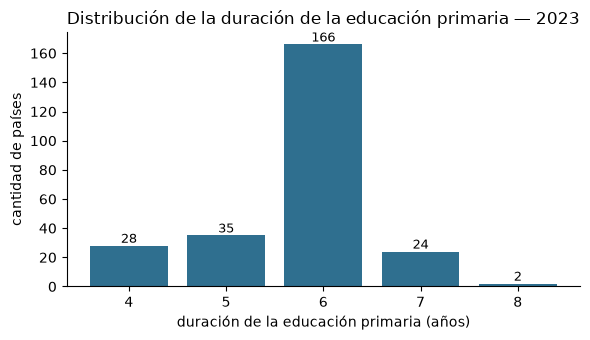

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
conteo = primaria["duracion_primaria_anios"].value_counts().sort_index()
ax.bar(conteo.index.astype(str), conteo.values, color="#2f6f8f")
for x, y in zip(conteo.index.astype(str), conteo.values):
    ax.text(x, y + 2, str(y), ha="center", fontsize=9)
ax.set_xlabel("duración de la educación primaria (años)")
ax.set_ylabel("cantidad de países")
ax.set_title("Distribución de la duración de la educación primaria — 2023")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Respuesta 3

**Distribución.** El valor modal es **6 años** (166 países, 65 % del total con dato), seguido
por 5 años (35), 7 años (24) y 4 años (28); solo dos casos —Guam e Irlanda— llegan a 8 años, el
máximo del dataset. La duración mínima observada es 4 años. El ranking completo queda en
`salida/educacion_primaria_2023.csv`; el fragmento de arriba muestra el extremo superior
(empatado en 8 y 7 años).

<a id="reflexion"></a>

---

## Reflexión sobre el paradigma programático

Los tres ejercicios comparten una estructura muy uniforme en pandas: **seleccionar columnas →
limpiar → deduplicar → (filtrar/ordenar) → escribir**, y cada paso es una o dos líneas
encadenables. Dos observaciones puntuales, que se retoman con más detalle en el informe
comparativo:

- La limpieza por regex del Ejercicio 2 (`re.sub` + `.str.contains` para depurar) se escribe y
  se prueba en el mismo lugar donde se ve el resultado —la celda de `ejemplos` de más arriba
  existe justamente para eso—, sin salir del notebook.
- El dataset ancho (69 columnas) no exige declarar cada columna para poder ignorarla: `pandas`
  la lee completa y listas como `df[["Country Name", "Country Code"]]` seleccionan solo lo que
  hace falta. Esto es un contraste directo con el enfoque visual de Apache Hop, donde el *CSV
  file input* sí necesita las 69 columnas tipadas antes de poder descartar 65 de ellas con un
  *Select values* (ver `hop/pipelines/`).

<a id="referencias"></a>

---

## Referencias

- World Bank Group. *Education Statistics — All Indicators*.
  <https://data.worldbank.org/topic/education?view=chart>
- Apache Hop Project. *Apache Hop Documentation*. <https://hop.apache.org/manual/latest/>
- Kimball, R. y Caserta, J. (2004). *The Data Warehouse ETL Toolkit*. Wiley.